# Example 28

An example that shows only three tallies. 

In [1]:
import openmc 
import numpy as np

# Material definitions
materials=openmc.Materials()

m999 = openmc.Material()
m999.add_nuclide('O16', 8)
m999.add_nuclide('H1', 1)
m999.set_density('g/cc',1.0)

m1001 = openmc.Material()
m1001.add_nuclide('U238', 0.9)
m1001.add_nuclide('U235', 0.5)
m1001.set_density('g/cc',5.0)
materials.append(m1001)

In [2]:
# Surface definition
s1 = openmc.Sphere(r=5)
s2 = openmc.Sphere(r=6,boundary_type='vacuum')

# Cell definition
c10 = openmc.Cell(fill=m999,region=-s1) 
c11 = openmc.Cell(fill=None,region=+s1&-s2) 
c12 = openmc.Cell(fill=None,region=+s2) 
geometry=openmc.Geometry([c10,c11,c12])

Just as in the last example, we have an f1:n filter applied to surface 1. But we also have an Fn:P filter applied to (x,y,z,r) = (0,0,0,0) which is a point detector. 
This point detector is assigned "25" for its tally number, and then multiplied by the tally multiplier FM25 0.00253 1001 -6 -8. The numbers means the atoms per barn/cm, the material number for heating, the reaction number for total fission cross section, and the reaction number for fission Q.

In [3]:
# Tally creation
f1_filter = openmc.SurfaceFilter(bins=s1)
f1 = openmc.Tally(name="f1",scores=['current'],filters=[f1_filter])

f25_filter = openmc.CellFilter(bins=[c10])
f4 = openmc.Tally(name="f4", scores=['(n,gamma)'],filters=[f4_filter])
tallies = openmc.Tallies(tallies=[f1,f4])

The specification for the source below matches MCNP's SDEF, which is a 14 MeV isotropic source, sampled within the cell that contains the point (0,0,0). 

In [4]:
settings = openmc.Settings()
settings.run_mode='fixed source'

# Source specification
source = openmc.IndependentSource()
source.space = openmc.stats.spherical_uniform(r_outer = 5, r_inner = 0) # the cell is spherical
source.angle = openmc.stats.Isotropic() 
source.energy = openmc.stats.delta_function(14e6) # energy in eV 
settings.source = source

In [5]:
model = openmc.model.Model()
model.geometry = geometry
model.materials = materials
model.tallies = tallies

settings.particles = 100
settings.batches = 20

model.settings=settings

In [6]:
w = 45
plots = openmc.Plots()

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
#plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level = level
#plots.append(plot)

model.plots = plots

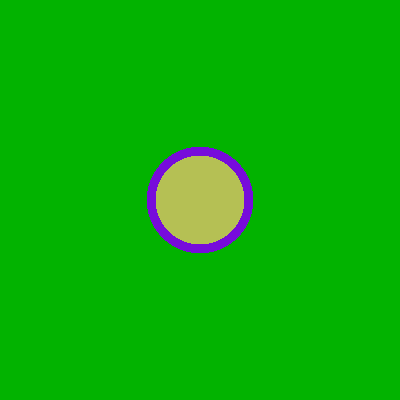

In [7]:
model.export_to_xml()
openmc.plot_inline(plots)

Tally post-processing:

model.run() will return the resulting statepoint.h5 file that contains all of the results. 

In [8]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [10]:
# open the results file
with openmc.StatePoint(sp_filename) as sp:

    # access the tally using pandas dataframes
    f1_tally = sp.get_tally(name='f1')
    df = f1_tally.get_pandas_dataframe()

    print(df)

    f4_tally = sp.get_tally(name='f4')
    df = f4_tally.get_pandas_dataframe()
    
    print(df)

   surface nuclide    score     mean  std. dev.
0        1   total  current 1.36e+00   2.41e-02
   cell nuclide      score     mean  std. dev.
0     1   total  (n,gamma) 3.53e-03   3.08e-04


/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
